In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from datetime import datetime 

In [2]:
data = pd.read_csv("AirPassengers.csv")
data.head(2)

,Month,Passengers
0,1949-01,112
1,1949-02,118


In [3]:
data = pd.read_csv('AirPassengers.csv',index_col=[0],parse_dates=True)

In [4]:
data.tail()

,Passengers
Month,
1960-08-01,606
1960-09-01,508
1960-10-01,461
1960-11-01,390
1960-12-01,432


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Passengers  144 non-null    int64
dtypes: int64(1)
memory usage: 2.2 KB


In [6]:
data.describe()

,Passengers
count,144.000000
mean,280.298611
std,119.966317
min,104.000000
25%,180.000000
50%,265.500000
75%,360.500000
max,622.000000


In [7]:
data.isna().sum()

Passengers    0
dtype: int64

In [8]:
data.shape

(144, 1)

In [9]:
data.columns

Index(['Passengers'], dtype='object')

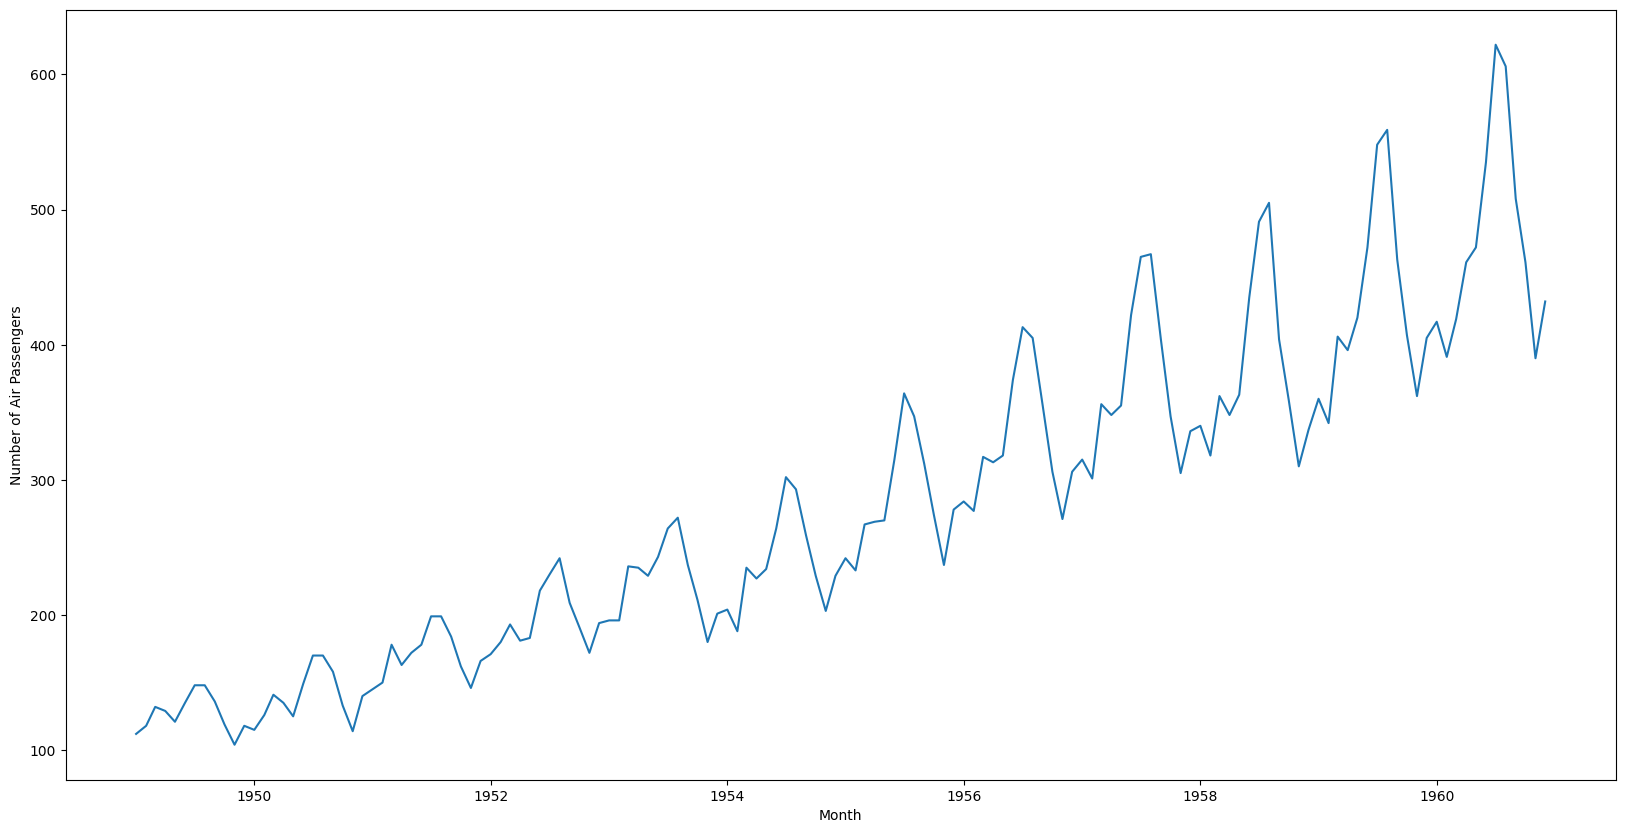

In [ ]:
plt.figure(figsize=(20,10))
plt.xlabel("Month")
plt.ylabel("Number of Air Passengers")
plt.plot(data)
plt.show()

In [12]:
## Differencing 

In [ ]:
## First Difference
data['Passengers First Difference'] = data['Passengers'] - data['Passengers'].shift(1)

In [14]:
data.head()

,Passengers,Passengers First Difference
Month,,
1949-01-01,112,NaN
1949-02-01,118,6.0
1949-03-01,132,14.0
1949-04-01,129,-3.0
1949-05-01,121,-8.0


In [15]:
## Testing For stationarity
from statsmodels.tsa.stattools import adfuller

In [16]:
def adfuller_test(Passengers):
  result=adfuller(Passengers)
  labels = ['ADF Test Statistic','p-value','#Lags Used','Number of Observations Used']
  for value , label in zip(result,labels):
    print(label+" : "+str(value) )
  if result[1] <= 0.05:
    print("Data has no unit root and is stationary")
  else:
    print("Data has no unit root indicating it is non-stationary")

In [17]:
adfuller_test(data['Passengers First Difference'].dropna())

ADF Test Statistic : -2.8292668241699994
p-value : 0.0542132902838255
#Lags Used : 12
Number of Observations Used : 130
Data has no unit root indicating it is non-stationary


C:\Users\HP\AppData\Local\Temp\ipykernel_21128\3968434515.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result=adfuller(Passengers)


In [18]:
## Use Techniques Differencing 
data['Passengers Second Difference'] = data['Passengers First Difference']-data['Passengers First Difference'].shift(1)
data.head(5)

,Passengers,Passengers First Difference,Passengers Second Difference
Month,,,
1949-01-01,112,NaN,NaN
1949-02-01,118,6.0,NaN
1949-03-01,132,14.0,8.0
1949-04-01,129,-3.0,-17.0
1949-05-01,121,-8.0,-5.0


In [19]:
adfuller_test(data['Passengers Second Difference'].dropna())

ADF Test Statistic : -16.384231542468505
p-value : 2.7328918500142407e-29
#Lags Used : 11
Number of Observations Used : 130
Data has no unit root and is stationary


C:\Users\HP\AppData\Local\Temp\ipykernel_21128\3968434515.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result=adfuller(Passengers)


In [ ]:
## ARIMA  
## AR (P) = 5 , I(D) = 2 , MA(Q) = 7

In [20]:
## ACF  and PACF PLOT (AUTO CORELATION PLOT NAD PARTIA LAUTO CORELATION PLOT)

In [21]:
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf

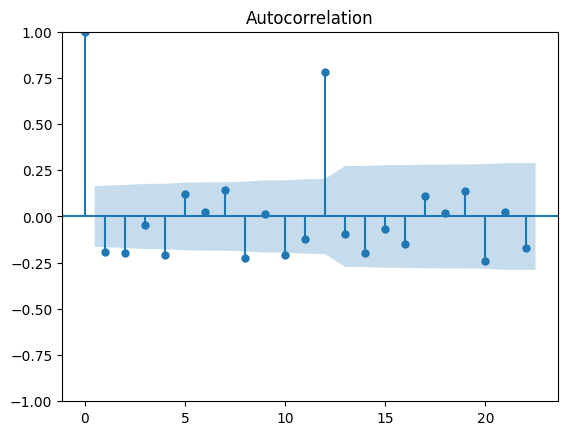

In [22]:
acf = plot_acf(data["Passengers Second Difference"].dropna())

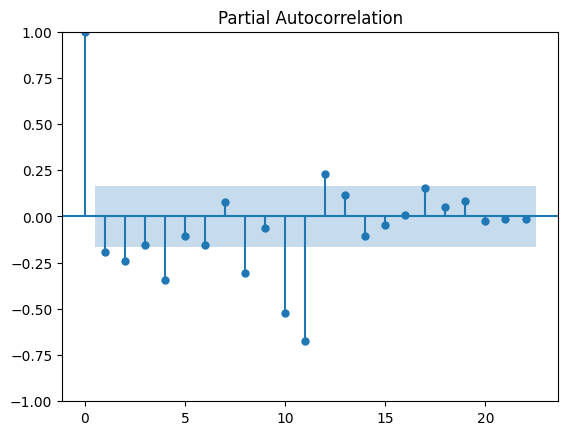

In [23]:
result = plot_pacf(data['Passengers Second Difference'].dropna())

In [24]:
## Create ARIMA model
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(data['Passengers'],order=(5,2,7))
model_fit=model.fit()

C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [34]:
# model_fit.summary()
print(model_fit.aic)
print(model_fit.bic)
print(model_fit.params)

1337.5517242385731
1375.9774759873894
ar.L1      -0.321202
ar.L2       0.345780
ar.L3       0.442614
ar.L4      -0.004934
ar.L5      -0.634028
ma.L1      -0.651847
ma.L2      -1.144026
ma.L3      -0.284150
ma.L4       0.509785
ma.L5       1.453762
ma.L6      -0.339623
ma.L7      -0.543614
sigma2    520.148425
dtype: float64


In [26]:
data.shape

(144, 3)

<Axes: xlabel='Month'>

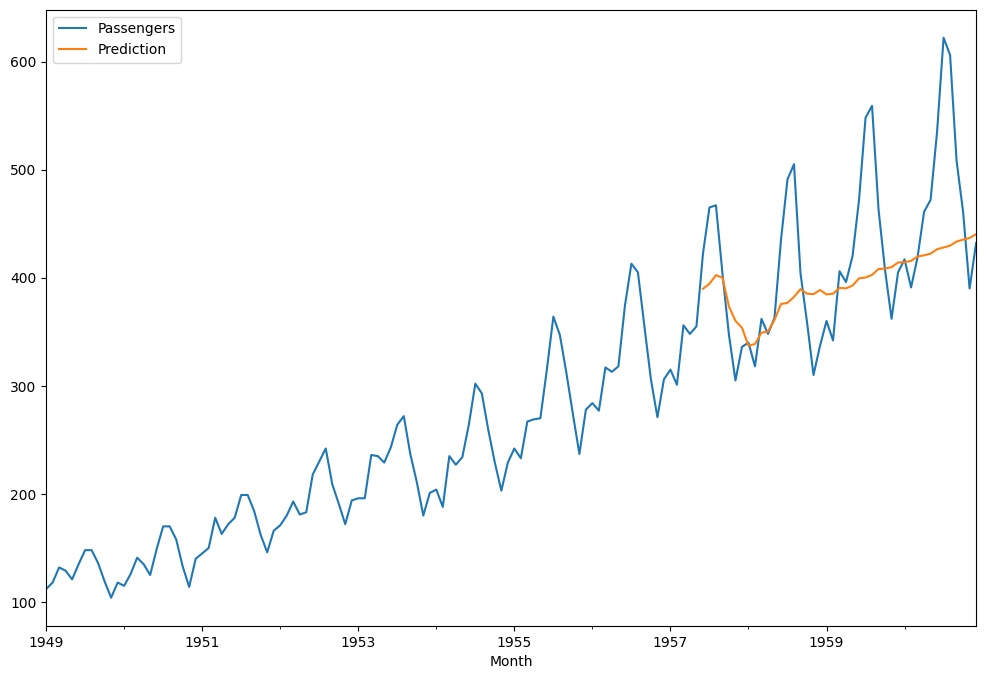

In [27]:
data['Prediction'] = model_fit.predict(start=101,end=144,dynamic=True)
data[['Passengers','Prediction']].plot(figsize=(12,8))

In [28]:
### SARIMAX

In [29]:
import statsmodels.api as sm
model = sm.tsa.statespace.SARIMAX(data['Passengers'],order=(5,2,7),seasonal_order=(5,2,7,12))
results = model.fit()

C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


<Axes: xlabel='Month'>

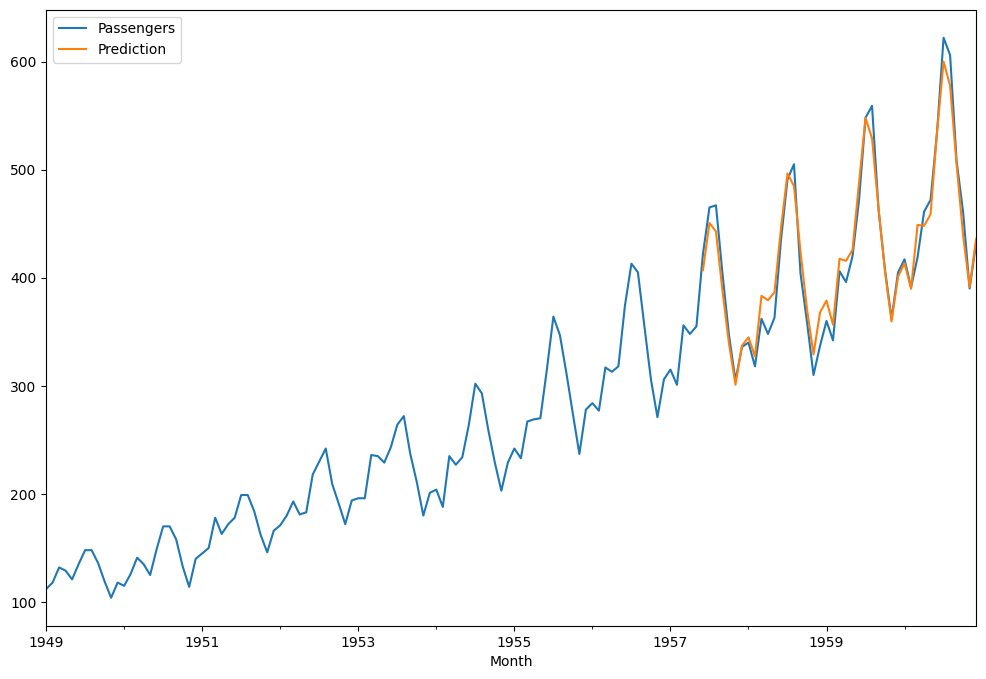

In [30]:
data['Prediction'] = results.predict(start=101,end=145,dynamic=True)
data[['Passengers','Prediction']].plot(figsize=(12,8))

In [31]:
## Forecasting

In [32]:
from pandas.tseries.offsets import DateOffset
future_dates=[data.index[-1]+ DateOffset(months=x) for x in range(0,24)]

In [33]:
future_datest_df = pd.DataFrame(index=future_dates[1:],columns=data.columns)

In [35]:
future_df = pd.concat([data,future_datest_df])

C:\Users\HP\AppData\Local\Temp\ipykernel_21128\2405087247.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  future_df = pd.concat([data,future_datest_df])


In [38]:
future_df

,Passengers,Passengers First Difference,Passengers Second Difference,Prediction
1949-01-01,112,NaN,NaN,NaN
1949-02-01,118,6.0,NaN,NaN
1949-03-01,132,14.0,8.0,NaN
1949-04-01,129,-3.0,-17.0,NaN
1949-05-01,121,-8.0,-5.0,NaN
...,...,...,...,...
1962-07-01,NaN,NaN,NaN,NaN
1962-08-01,NaN,NaN,NaN,NaN
1962-09-01,NaN,NaN,NaN,NaN
1962-10-01,NaN,NaN,NaN,NaN


<Axes: >

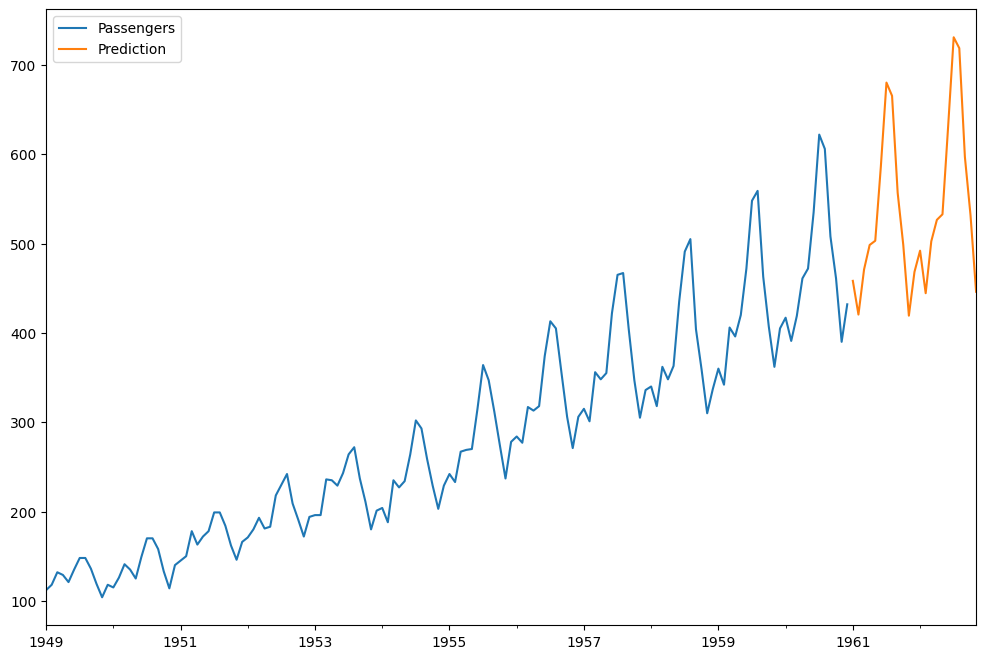

In [39]:
future_df['Prediction'] = results.predict(start = 144, end = 200 , dynamic=True)
future_df[['Passengers','Prediction']].plot(figsize=(12,8))